In [1]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader, TensorDataset, random_split, Subset
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import joblib
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Using device: cuda


In [2]:
import pandas as pd
import numpy as np
import joblib
from sklearn.preprocessing import MinMaxScaler

def generate_safe_house_mock_fixed(days=30):
    data = []

    sensor_cols = [f'sensor_{i}' for i in range(7)]
    location_cols = [f'location_{i}' for i in range(7)]
    columns = sensor_cols + location_cols + ['hour_sin', 'hour_cos', 'day_sin', 'day_cos']

    current_location = 5

    for day in range(days):
        day_of_week = day % 7
        for hour in range(24):
            for minute in range(60):
                # Time encoding including minutes to exactly match inference behavior in data_preprocessing.py
                hour_frac = hour + minute / 60.0
                h_sin = np.sin(2 * np.pi * hour_frac / 24)
                h_cos = np.cos(2 * np.pi * hour_frac / 24)
                d_sin = np.sin(2 * np.pi * day_of_week / 7)
                d_cos = np.cos(2 * np.pi * day_of_week / 7)

                events = [0] * 7
                target_location = current_location

                if 0 <= hour < 7:
                    target_location = 5
                    if np.random.rand() > 0.998: target_location = 3

                elif 7 <= hour < 9:
                    if minute < 10: target_location = 5
                    elif minute < 20: target_location = 3
                    elif minute < 40: target_location = 1
                    else: target_location = 6

                elif 10 <= hour < 16:
                    if 11 <= hour < 13:
                        target_location = -1
                    else:
                        if np.random.rand() > 0.98:
                            target_location = 6 if np.random.rand() > 0.5 else 1

                elif 17 <= hour < 23:
                    if hour == 21 and minute < 20: target_location = 2
                    elif hour >= 22 and minute > 30: target_location = 5
                    else: target_location = 6

                # Meds routine (index 4) - morning and evening sessions
                is_meds_time = (hour == 8 and 30 <= minute < 32) or (hour == 20 and 0 <= minute < 2)
                if is_meds_time:
                    target_location = 4

                if target_location != current_location:
                    if target_location != -1:
                        events[target_location] = 1

                    if target_location == -1 and current_location != -1:
                        events[0] = 1
                    elif current_location == -1 and target_location != -1:
                        events[0] = 1

                    current_location = target_location
                else:
                    if current_location != -1 and np.random.rand() > 0.98:
                        events[current_location] = 1

                # Random noise
                if np.random.rand() > 0.999:
                    events[np.random.randint(0, 7)] = 1

                location_state = [0] * 7
                if current_location != -1:
                    location_state[current_location] = 1

                row = events + location_state + [h_sin, h_cos, d_sin, d_cos]
                data.append(row)

    return pd.DataFrame(data, columns=columns)

# Ensure reproducibility
np.random.seed(42)
df_clean = generate_safe_house_mock_fixed(30)
print(f"✅ Data generated, shape: {df_clean.shape}")

# Sanity check: Meds events
_s4 = df_clean['sensor_4']
_rising = ((_s4 == 1) & (_s4.shift(1, fill_value=0) == 0)).sum()
print(f"💊 Total meds events (rising edges) in 30 days: {_rising} (~{_rising/30:.1f}/day)")

scaler = MinMaxScaler()

scaled_values = scaler.fit_transform(df_clean)
df_final_scaled = pd.DataFrame(scaled_values, columns=df_clean.columns)

joblib.dump(scaler, 'scaler.pkl')
print("✅ Data normalized and scaler.pkl saved successfully!")

✅ Data generated, shape: (43200, 18)
💊 Total meds events (rising edges) in 30 days: 64 (~2.1/day)
✅ Data normalized and scaler.pkl saved successfully!


In [3]:
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset

def create_sequences(data, window_size=360):
    """
    Creates rolling window sequences for LSTM.
    Input: DataFrame or 2D Numpy Array
    Output: 3D Numpy Array [Samples, Time_Steps, Features]
    """
    if hasattr(data, 'values'):
        data = data.values

    sequences = []
    for i in range(len(data) - window_size + 1):
        window = data[i : i + window_size]
        sequences.append(window)

    return np.array(sequences)

# Window size: 6 hours = 360 minutes
WINDOW_SIZE = 360

X_train = create_sequences(df_final_scaled, window_size=WINDOW_SIZE)

# Convert to PyTorch tensors (Float32). Kept on CPU initially to avoid memory overflow.
X_tensor = torch.tensor(X_train, dtype=torch.float32)

# Create DataLoader. For an Autoencoder, target (Y) is identical to input (X).
batch_size = 64
train_dataset = TensorDataset(X_tensor, X_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

print(f"✅ Sequence creation completed!")
print(f"📊 Final tensor shape: {X_tensor.shape}")
print(f"📦 Number of training batches: {len(train_loader)}")

✅ Sequence creation completed!
📊 Final tensor shape: torch.Size([42841, 360, 18])
📦 Number of training batches: 670


In [4]:
import torch
import torch.nn as nn

class Encoder(nn.Module):
    def __init__(self, seq_len, n_features, embedding_dim=64):
        super(Encoder, self).__init__()
        self.seq_len, self.n_features = seq_len, n_features
        self.embedding_dim, self.hidden_dim = embedding_dim, 2 * embedding_dim

        self.rnn1 = nn.LSTM(input_size=n_features, hidden_size=self.hidden_dim, num_layers=1, batch_first=True)
        # Dropout added to prevent overfitting
        self.dropout = nn.Dropout(0.2)
        self.rnn2 = nn.LSTM(input_size=self.hidden_dim, hidden_size=embedding_dim, num_layers=1, batch_first=True)

    def forward(self, x):
        x, _ = self.rnn1(x)
        x = self.dropout(x)
        x, (hidden_n, _) = self.rnn2(x)
        return hidden_n.reshape((x.shape[0], 1, self.embedding_dim))

class Decoder(nn.Module):
    # Signature must exactly match ai_handler.py on the server
    def __init__(self, seq_len, embedding_dim=64, n_features=18):
        super(Decoder, self).__init__()
        self.seq_len, self.embedding_dim = seq_len, embedding_dim
        self.hidden_dim, self.n_features = 2 * embedding_dim, n_features

        self.rnn1 = nn.LSTM(input_size=embedding_dim, hidden_size=embedding_dim, num_layers=1, batch_first=True)
        self.dropout = nn.Dropout(0.2)
        self.rnn2 = nn.LSTM(input_size=embedding_dim, hidden_size=self.hidden_dim, num_layers=1, batch_first=True)

        self.output_layer = nn.Linear(self.hidden_dim, n_features)
        # Essential: bounds the output between 0 and 1 for normalized features
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = x.repeat(1, self.seq_len, 1)
        x, _ = self.rnn1(x)
        x = self.dropout(x)
        x, _ = self.rnn2(x)
        x = self.output_layer(x)
        return self.sigmoid(x)

class LSTMAnomalyDetector(nn.Module):
    def __init__(self, seq_len, n_features, embedding_dim=64):
        super(LSTMAnomalyDetector, self).__init__()
        self.encoder = Encoder(seq_len, n_features, embedding_dim)
        self.decoder = Decoder(seq_len, embedding_dim, n_features)

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

def train_model(model, train_loader, val_loader, n_epochs=100):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)

    # Added weight_decay for L2 regularization
    optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
    criterion = nn.MSELoss()

    history = {'train': [], 'val': []}
    best_loss = float('inf')
    patience = 10
    counter = 0

    for epoch in range(n_epochs):
        model.train()
        train_losses = []
        for x_batch, _ in train_loader:
            x_batch = x_batch.to(device)
            optimizer.zero_grad()

            output = model(x_batch)
            loss = criterion(output, x_batch)

            loss.backward()

            # Gradient Clipping to prevent exploding gradients in LSTM
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            optimizer.step()
            train_losses.append(loss.item())

        model.eval()
        val_losses = []
        with torch.no_grad():
            for x_val, _ in val_loader:
                x_val = x_val.to(device)
                output = model(x_val)
                loss = criterion(output, x_val)
                val_losses.append(loss.item())

        train_loss = np.mean(train_losses)
        val_loss = np.mean(val_losses)
        history['train'].append(train_loss)
        history['val'].append(val_loss)

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f'Epoch {epoch+1}: Train Loss {train_loss:.6f} | Val Loss {val_loss:.6f}')

        # Save the best model based on validation loss
        if val_loss < best_loss:
            best_loss = val_loss
            torch.save(model.state_dict(), 'best_safe_house_model.pth')
            counter = 0
        else:
            counter += 1
            if counter >= patience:
                print(f"🛑 Early Stopping triggered at epoch {epoch+1}")
                break

    return history

Epoch 1: Train Loss 0.067471 | Val Loss 0.063769
Epoch 5: Train Loss 0.024330 | Val Loss 0.021611
Epoch 10: Train Loss 0.011614 | Val Loss 0.011860
Epoch 15: Train Loss 0.011284 | Val Loss 0.012048
Epoch 20: Train Loss 0.009562 | Val Loss 0.011303
Epoch 25: Train Loss 0.008080 | Val Loss 0.010938
Epoch 30: Train Loss 0.008245 | Val Loss 0.010006
Epoch 35: Train Loss 0.008178 | Val Loss 0.010474
🛑 Early Stopping triggered at epoch 36


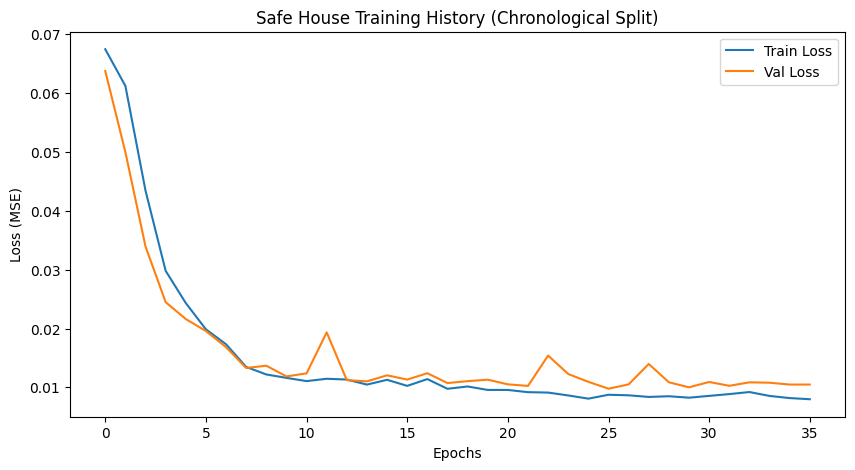

In [6]:
SEQ_LEN = 360
N_FEATURES = 18
EMBEDDING_DIM = 64

# Critical fix: Chronological split instead of random split
dataset_size = len(train_dataset)
train_size = int(0.8 * dataset_size)

# Leave a gap of SEQ_LEN between train and validation to prevent data leakage
# due to overlapping windows (stride=1)
train_indices = list(range(0, train_size))
val_indices = list(range(train_size + SEQ_LEN, dataset_size))

train_sub = Subset(train_dataset, train_indices)
val_sub = Subset(train_dataset, val_indices)

# shuffle=True is safe and recommended for train_loader now because the sets are completely isolated
train_loader = DataLoader(train_sub, batch_size=64, shuffle=True)
val_loader = DataLoader(val_sub, batch_size=64, shuffle=False)

model = LSTMAnomalyDetector(SEQ_LEN, N_FEATURES, EMBEDDING_DIM)
history = train_model(model, train_loader, val_loader, n_epochs=50)

plt.figure(figsize=(10, 5))
plt.plot(history['train'], label='Train Loss')
plt.plot(history['val'], label='Val Loss')
plt.title('Safe House Training History (Chronological Split)')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.show()

In [7]:
import joblib
joblib.dump(scaler, 'scaler.pkl')
print("Scaler saved!")

Scaler saved!


In [8]:
import torch

def run_system_tests(scaler, model, device):
    print("--- Starting SAFE HOUSE system tests ---")

    # ==========================================
    # Test 1: Normal Routine (Expecting low anomaly score)
    # ==========================================
    df_normal = generate_safe_house_mock_fixed(days=1)

    # Time window: 18:00 to 00:00, centered around 21:00 (minute 1260)
    start_minute = 21 * 60

    scaled_normal = scaler.transform(df_normal)
    normal_seq = scaled_normal[start_minute - 180 : start_minute + 180]
    normal_tensor = torch.tensor(normal_seq, dtype=torch.float32).unsqueeze(0).to(device)

    # ==========================================
    # Test 2: Severe Anomaly (Expecting high anomaly score)
    # ==========================================
    df_anomaly = generate_safe_house_mock_fixed(days=1)
    end_minute = start_minute + 180

    # Reset locations from 21:00 onwards
    for i in range(7):
        df_anomaly.loc[start_minute:end_minute, f'location_{i}'] = 0
        df_anomaly.loc[start_minute+1:end_minute, f'sensor_{i}'] = 0

    # Inject anomaly: Stuck in the shower for 3 hours (sensor_2/location_2)
    df_anomaly.loc[start_minute, 'sensor_2'] = 1
    df_anomaly.loc[start_minute:end_minute, 'location_2'] = 1

    scaled_anomaly = scaler.transform(df_anomaly)
    anomaly_seq = scaled_anomaly[start_minute - 180 : start_minute + 180]
    anomaly_tensor = torch.tensor(anomaly_seq, dtype=torch.float32).unsqueeze(0).to(device)

    # ==========================================
    # Model Evaluation
    # ==========================================
    model.eval()
    with torch.no_grad():
        pred_normal = model(normal_tensor)
        norm_actual_locs = normal_tensor[0, -30:, 7:14]
        norm_pred_locs = pred_normal[0, -30:, 7:14]
        normal_smart_score = torch.mean((norm_pred_locs - norm_actual_locs)**2).item()

        pred_anomaly = model(anomaly_tensor)
        anom_actual_locs = anomaly_tensor[0, -30:, 7:14]
        anom_pred_locs = pred_anomaly[0, -30:, 7:14]
        anomaly_smart_score = torch.mean((anom_pred_locs - anom_actual_locs)**2).item()

    # ==========================================
    # Print Results
    # ==========================================
    print("\n✅ Test 1 Results: Normal Routine")
    print(f"   Anomaly Score: {normal_smart_score:.6f}")

    print("\n🚨 Test 2 Results: Life-Threatening Anomaly (3 hours in shower)")
    print(f"   Anomaly Score: {anomaly_smart_score:.6f}")

    # Ratio check (added 1e-8 to prevent division by zero)
    ratio = anomaly_smart_score / (normal_smart_score + 1e-8)
    print(f"\n📊 Summary: Anomaly score is {ratio:.1f}x higher than the normal routine!")

run_system_tests(scaler, model, device)

--- Starting SAFE HOUSE system tests ---

✅ Test 1 Results: Normal Routine
   Anomaly Score: 0.000039

🚨 Test 2 Results: Life-Threatening Anomaly (3 hours in shower)
   Anomaly Score: 0.237365

📊 Summary: Anomaly score is 6093.4x higher than the normal routine!
